In [ ]:
import os, sys, glob
os.environ['R_HOME'] = sys.exec_prefix + '/lib/R/'
import numpy as np, pandas as pd
import scanpy as sc, scanpy.external as sce, scFates as scf
import matplotlib.pyplot as plt
from scipy.stats import spearmanr
sc.settings.verbosity = 1
SEED = 1; np.random.seed(SEED)

In [ ]:
name = os.path.basename(os.getcwd())
cat  = os.path.basename(os.path.dirname(os.getcwd()))
pth  = os.path.join(*([os.pardir]*4))
pth_data = os.path.join(pth, 'data')
pth_out = os.path.join(pth_data, 'cancer', 'vertebrate', 'CCCA', 'claude', cat, name)
pth_fig = os.path.join(pth, 'figures', 'mesencontext', 'claude', cat, name)
os.makedirs(pth_fig, exist_ok=True)

In [ ]:
# EMT-TF step is unconditional (last notebook, here #04 since Gate 3 is NA).
# read from processed.h5ad (raw manifold); reuse the house linear layout + pseudotime.
adata = sc.read_h5ad(os.path.join(pth_out, 'signatures.h5ad'))
adata.obsm['X_umap'] = adata.obsm['X_umap_lin']
t = adata.obs['t'].values; tn = (t - t.min())/(t.max() - t.min())
print('cells:', adata.shape[0], '| pseudotime', round(t.min(), 2), '->', round(t.max(), 2))

cells: 4985 | pseudotime 0.0 -> 10.28


In [ ]:
# widened EMT-TF panel gated on detectable expression (eval lesson: include FOXC/PRRX
# mesenchymal families, not only Snail/Zeb/Twist). VIM excluded (a marker, not a TF).
# per-TF: detection frac, pseudotime trend (rho), and enriched-end bias.
panel = ['SNAI1', 'SNAI2', 'ZEB1', 'ZEB2', 'TWIST1', 'TWIST2',
         'FOXC1', 'FOXC2', 'PRRX1', 'PRRX2']
present = [g for g in panel if g in adata.var_names]
early = tn <= np.quantile(tn, 1/3); late = tn >= np.quantile(tn, 2/3)
X = adata[:, present].X; X = X.toarray() if hasattr(X, 'toarray') else np.asarray(X)
rows = []
for j, g in enumerate(present):
    x = X[:, j]; rho, p = spearmanr(tn, x); me, ml = x[early].mean(), x[late].mean()
    bias = (ml - me)/(ml + me + 1e-9)                      # +1 pure terminus, -1 pure root
    rows.append((g, round((x > 0).mean(), 3), round(me, 3), round(ml, 3),
                 round(rho, 3), round(bias, 3)))
df = pd.DataFrame(rows, columns=['TF', 'frac_expr', 'mean_early', 'mean_late', 'rho_vs_t', 'end_bias'])
df = df.sort_values('rho_vs_t')
print(df.to_string(index=False))
# only 3 EMT-TFs are detectable (frac>0.03): ZEB1/ZEB2 broadly pan-tumor, PRRX1 terminus-enriched.
# the Snail/Twist/FoxC families are essentially absent -> a real dataset-specific readout.
ok = df[df.frac_expr > 0.03].copy()
tf_lo = ok.sort_values('rho_vs_t').iloc[0]['TF']          # most root-trending detectable factor
tf_hi = ok.sort_values('rho_vs_t').iloc[-1]['TF']         # most terminus-trending detectable factor
def _end_label(g):
    b = float(ok.loc[ok.TF == g, 'end_bias'].iloc[0])
    return 'terminus' if b > 0.05 else ('root' if b < -0.05 else 'pan-tumor')
lab_lo, lab_hi = _end_label(tf_lo), _end_label(tf_hi)
print(f'\ndetectable factors: {ok.TF.tolist()}')
print(f'derived pair: {tf_lo} ({lab_lo}) <-> {tf_hi} ({lab_hi})')
print('note: canonical EMT-TFs are broadly expressed here; PRRX1 alone tracks the terminus.')

    TF  frac_expr  mean_early  mean_late  rho_vs_t  end_bias
TWIST2      0.002       0.007      0.005    -0.008    -0.142
 SNAI2      0.020       0.077      0.068     0.005    -0.060
 FOXC1      0.006       0.007      0.009     0.017     0.126
TWIST1      0.010       0.023      0.025     0.020     0.037
 PRRX2      0.001       0.000      0.005     0.027     1.000
 FOXC2      0.005       0.008      0.020     0.031     0.419
 SNAI1      0.015       0.021      0.051     0.050     0.424
  ZEB1      0.912       3.823      4.445     0.108     0.075
  ZEB2      0.908       3.431      4.164     0.144     0.097
 PRRX1      0.434       0.850      1.437     0.194     0.257

detectable factors: ['ZEB1', 'ZEB2', 'PRRX1']
derived pair: ZEB1 (terminus) <-> PRRX1 (terminus)
note: canonical EMT-TFs are broadly expressed here; PRRX1 alone tracks the terminus.


overlay thresholds (top decile among expressers): {'ZEB1': 5.9, 'PRRX1': 4.3} | cells shown: {'ZEB1': 455, 'PRRX1': 217}
ZEB1: 91.2% expressing; 455 shown (top decile), mean pseudotime of shown = 0.49 (all = 0.51)
PRRX1: 43.4% expressing; 217 shown (top decile), mean pseudotime of shown = 0.52 (all = 0.51)
saved expression.pdf


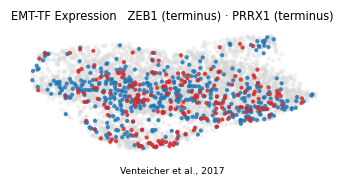

In [ ]:
# deliverable: expression.pdf — categorical overlay of thresholded expressers on a grey
# manifold (house 3.5,1.5), NOT a continuous colormap. threshold = upper quartile among
# expressing cells, per module.
xl = adata.obsm['X_umap']
xlo, xhi = np.percentile(xl[:, 0], [0.3, 99.7]); ylo, yhi = np.percentile(xl[:, 1], [0.3, 99.7])
px = (xhi-xlo)*.05; py = (yhi-ylo)*.08
def _vec(g):
    x = adata[:, g].X
    return x.toarray().ravel() if hasattr(x, 'toarray') else np.asarray(x).ravel()
# display the TOP DECILE among expressers so a broadly-expressed factor (ZEB1) is not
# washed across the whole manifold -> comparable, legible cell counts per factor.
thr = {}
for g in [tf_lo, tf_hi]:
    v = _vec(g); pos = v[v > 0]; thr[g] = float(np.quantile(pos, 0.90)) if pos.size else 0.0
sel = {g: _vec(g) > thr[g] for g in [tf_lo, tf_hi]}
print('overlay thresholds (top decile among expressers):', {g: round(thr[g], 2) for g in thr},
      '| cells shown:', {g: int(sel[g].sum()) for g in sel})
order = sorted([tf_lo, tf_hi], key=lambda g: -int(sel[g].sum()))
colors = {tf_lo: 'tab:blue', tf_hi: 'tab:red'}
labs = {tf_lo: lab_lo, tf_hi: lab_hi}
fig, ax = plt.subplots(figsize=(3.5, 1.5))
sc.pl.umap(adata, size=30, alpha=.3, frameon=False, show=False, ax=ax, na_color='lightgray')
for g in order:
    ap = adata[sel[g]].copy()
    sc.pl.umap(ap, na_color=colors[g], size=30, alpha=.85, frameon=False, show=False, ax=ax)
ax.set_xlim(xlo-px, xhi+px); ax.set_ylim(ylo-py, yhi+py)
ax.set_title(f'EMT-TF Expression   {tf_lo} ({labs[tf_lo]}) \u00b7 {tf_hi} ({labs[tf_hi]})', size=7.5)
ax.text(.5, -.14, 'Venteicher et al., 2017', ha='center', transform=ax.transAxes, size=6)
fig.savefig(os.path.join(pth_fig, 'expression.pdf'), bbox_inches='tight')
for g in [tf_lo, tf_hi]:
    print(f'{g}: {(_vec(g)>0).mean()*100:.1f}% expressing; {int(sel[g].sum())} shown (top decile), '
          f'mean pseudotime of shown = {tn[sel[g]].mean():.2f} (all = {tn.mean():.2f})')
print('saved expression.pdf')